# Homework 4:  KNN Classification and a Streamlit Application

**Student Name: Anna Wadlow**

Name your homework ``.ipynb`` file using the following format un: ``firstname-lastname-hw4.ipynb``

##  Objective

In this assignment, you will develop and deploy a classification application using Python, scikit-learn, and Streamlit. You will use the Palmer Penguins dataset to predict a penguin's species from its physical measurements and other characteristics.

The classification question is:

> Can the species of a penguin be accurately predicted from its physical measurements and other available characteristics?

You will apply the following ideas from the KNN labs:

- Data cleaning and preprocessing
- Encoding categorical variables
- Training and test-data splitting
- Feature standardization
- K-nearest-neighbors classification
- Cross-validation for selecting $K$
- Confusion matrices and classification reports
- Building and publicly deploying a Streamlit application

## Dataset

For this homework, you will use the Palmer Penguins dataset. The data contain observations from three penguin species: Adélie, Chinstrap, and Gentoo. The dataset includes bill measurements, flipper length, body mass, island, sex, and year. The data is publicly available at the following links

- [Palmer Penguins project page](https://allisonhorst.github.io/palmerpenguins/)
- [GitHub repository](https://github.com/allisonhorst/palmerpenguins)
- [Direct CSV file](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv)

The target variable is:

```python
species
```

The possible target classes are `Adelie`, `Chinstrap`, and `Gentoo`. Do not use `species` as a predictor.

## Variables

| Variable | Description |
|---|---|
| `species` | Penguin species; target variable |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimeters |
| `bill_depth_mm` | Bill depth in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `sex` | Penguin sex |
| `year` | Year of observation |

**Use the following code to import the data and show the data head and tail**(1 points)

In [ ]:
import pandas as pd


In [2]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

In [3]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [4]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


### 1. Obtain and describe the data (10 points)

Download the data from the given code below and report:

1. The number of observations and variables (2 points)
2. A description of each variable (2 points)
3. The target variable and its possible classes (2 points)
4. The number of observations in each class (2 points)
5. The number of missing values in each variable (2 points)



In [4]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

In [5]:
# 1. Number of observations and variables
df.shape
print(f"{df.shape[0]} rows and {df.shape[1]} variables, including the species type.")

344 rows and 8 variables, including the species type.


In [6]:
# 2. A description of each variable.
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [60]:
# 2 (cont'd). A description of each variable.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


**2 cont'd. Description of each variable**

| Variable | Type | Description |
|---|---|---|
| `species` | Categorical (target) | Penguin species: Adelie, Chinstrap, or Gentoo |
| `island` | Categorical | Island in the Palmer Archipelago where the penguin was observed: Biscoe, Dream, or Torgersen |
| `bill_length_mm` | Numeric (float) | Length of the bill, in millimeters |
| `bill_depth_mm` | Numeric (float) | Depth of the bill, in millimeters |
| `flipper_length_mm` | Numeric (float) | Length of the flipper, in millimeters |
| `body_mass_g` | Numeric (float) | Body mass, in grams |
| `sex` | Categorical | Penguin sex: female or male |
| `year` | Numeric (integer) | Year of observation: 2007, 2008, or 2009 |

In [7]:
# 3. The target variable and its possible classes.
print(f"We are predicting the species of penguin for which there are {df['species'].nunique()} possible classes: {', '.join(df['species'].unique())}")


We are predicting the species of penguin for which there are 3 possible classes: Adelie, Gentoo, Chinstrap


In [8]:
# 4. The number of observations in each class.
df.groupby("species")["species"].count()

species
Adelie       152
Chinstrap     68
Gentoo       124
Name: species, dtype: int64

In [14]:
# 5. The number of missing values in each variable.
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

## 2. Clean and prepare the data (15 points)

You should:

- Handle missing values appropriately (3 points)
- Separate the predictors from the target (1 points)
- Encode categorical variables such as `island` and `sex` (3 points)
- Split the data into training and test sets (3 points)
- Use a stratified split (1 point).
- Standardize the predictors through a scikit-learn pipeline (4 points)

Use the test set only for final evaluation. Do not use it to choose $K$ or make other modeling decisions.

In [146]:
# Imports
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
"""
Order of operations
0. Drop NaN rows
1. Separate X and y
2. Stratified train/test split
3. Define Pipeline (Encode and Standardize)
"""

In [ ]:
# 0. Drop NaN rows
# Rows with NaN in any column
print(df[df.isna().any(axis=1)])

# We drop rows with NaN in any column since kNN cannot use NaNs.
df_clean = df.dropna()

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
178  Gentoo     Biscoe            44.5           14.3              216.0   
218  Gentoo     Biscoe            46.2           14.4              214.0   
256  Gentoo     Biscoe            47.3           13.8              216.0   
268  Gentoo     Biscoe            44.5           15.7              217.0   
271  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  year  
3            NaN  NaN  2007  
8         3475.0  NaN  2007

In [ ]:
# 1. Separate predictors (X) from response (y)
X = df_clean.drop(columns=['species'])
y = df_clean['species']

In [164]:
# 2. Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=813, stratify=y)

In [165]:
# 3. Define Pipeline (Encode and Standardize)

# Identify which columns need what transformation
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['float64','int64']).columns.tolist()

# Bundle preprocessing for categorical and numerical data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols) 
        # handle_unknown='ignore' will output 0s for a category it hasn't seen before. sparse_output=False will return a dense matrix, which is easier to read and map back to data
    ]
)

# Preprocessing pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])


### 3. Build and tune a KNN classifier (25 points)

#### 3.1 Model definition and selection of $K$ (10 points)

Construct a pipeline containing `StandardScaler` and `KNeighborsClassifier`. Investigate several values of $K$, such as $K=1,2,\ldots,30$.

Use five-fold cross-validation on the training data to select the value of $K$ that gives the best validation performance. Include a plot of cross-validation error rate versus $K$.



In [166]:
# Pipeline with encoder, standardizer, and kNN classifier constructed above.
# Use GridSearchCV to automate hyperparameter tuning process

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid={'knn__n_neighbors': range(1,30)},
    cv=5, # 5-fold cross-validation
    scoring='accuracy' # Validation metric to optimize.
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': range(1, 30)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fit

In [183]:
print(f"Best K value: {grid_search.best_params_['knn__n_neighbors']}")
print(f"Best 5-fold validation accuracy: {grid_search.best_score_:.4f}")
print(f"Smallest CV error: {1-max(grid_search.cv_results_['mean_test_score']):.4f}")


Best K value: 8
Best 5-fold validation accuracy: 0.9962
Smallest CV error: 0.0038


In [168]:
knn_best = grid_search.best_estimator_


In [169]:
results = grid_search.cv_results_ # Save results from grid_search
k_values = results['param_knn__n_neighbors'].data # the k values tried
mean_scores = results['mean_test_score'] # mean accuracy across the 5 folds

cv_error = 1 - mean_scores

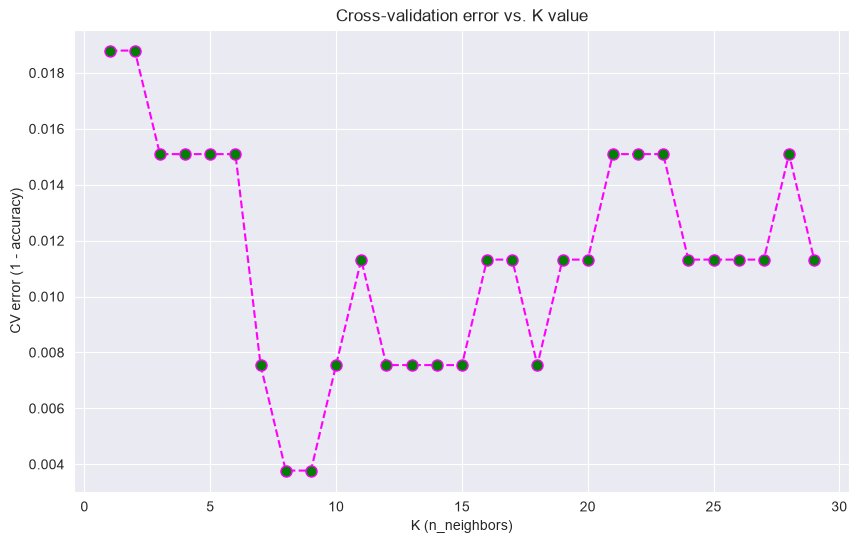

In [170]:
sns.set_style(style='darkgrid')
plt.figure(figsize=(10,6))
plt.plot(k_values, cv_error, color='magenta',ls='dashed',marker='o',markerfacecolor='green',markersize=8)
plt.xlabel('K (n_neighbors)')
plt.ylabel("CV error (1 - accuracy)")
plt.title('Cross-validation error vs. K value')
plt.show()

#### 3.2 Importance of standardization and appropriate value of $K$ (5 points)

Explain why standardization is important for KNN and why a very small or very large value of $K$ may not perform well.

- kNN makes decisions based on measured distance and thus, standardizing variables to be on comparable scales allows the measured distance to be truly meaningful and fair. 
- Small values of K cause a kNN model to follow the data very closely, which will result in overfitting. This type of model will have high variance, but low bias.
- Very large values of K cause a kNN model overgeneralize and lose nuance in the data. This type of model will have low variance, but high bias.

#### 3.3. Evaluate the final KNN model (10 points)

After selecting $K$, evaluate the final model on the test data. Report:

- Test accuracy (1 point)
- Test error rate (1 point)
- Confusion matrix (1 point)
- Precision, recall, and F1-score for each species (3 points)
- A written interpretation of the results (4 points)

In [179]:
pred = knn_best.predict(X_test)
print(f" Test accuracy is: {accuracy_score(y_test, pred):.4f}")
print(f" Test error rate is : {1 - accuracy_score(y_test, pred):.4f}")


 Test accuracy is: 0.9851
 Test error rate is : 0.0149


In [175]:
print(confusion_matrix(y_test, pred))

[[29  0  0]
 [ 1 13  0]
 [ 0  0 24]]


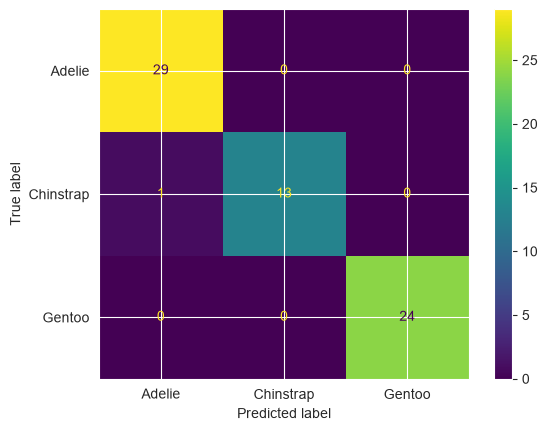

In [180]:
ConfusionMatrixDisplay.from_estimator(knn_best, X_test, y_test)

In [177]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        29
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        24

    accuracy                           0.99        67
   macro avg       0.99      0.98      0.98        67
weighted avg       0.99      0.99      0.98        67



### Interpretation
- For random state 813, the optimal K is 8. We see that this model has 100% precision for the Chinstrap and Gentoo classes, and 97% precision for the Adelie class.
- For the classes Adelie and Gentoo, the model has 100% recall, and for Chinstrap, it has 93% recall.
- From the confusion matrix, we see that there was one Chinstrap observation that was incorrectly labeled as Adelie. This accounts for the 97% Adelie precision, as 29/30 predicted were correct. It also explains the 93% Chinstrap recall, as the model found 13 out of the 14 Chinstrap observations.
- The F1-score is the harmonic mean of precision and recall, calculated as $\frac{2*P*R}{P+R}$. It is high, when both precision and recall are high. 
- Overall the model classifies penguin species very well. It achieved $66/67 \approx 98.5\%$ test accuracy and strong per-class precision, recall, and F1-scores. The error occurred as a Chinstrap misclassified as Adelie, which is likely due to the classes having overlapping measurements. The test size is small, so even one error affects the metrics a lot. The classes are also moderately imbalanced with 29, 14, and 24 observations in Adelie, Chinstrap, and Gentoo, respectively, and we therefore consider both the macro and weighted averages. They both agree in this case, so the imbalance isn't distorting the analysis.

### 4. Streamlit application (50 points)

Create an interactive Streamlit application that allows a user to enter the characteristics of a new penguin and receive a predicted species.

The application must include:

- A title and short description of the project
- Input widgets for the predictor variables
- A button labeled **Predict Species**
- The predicted penguin species
- Predicted probabilities for the three classes
- The value of $K$ selected by cross-validation
- A brief explanation of the prediction

The dataset may be loaded directly from the public URL using:

```python
data_url = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/main/inst/extdata/penguins.csv"
)
df = pd.read_csv(data_url)
```

The app must be deployed publicly using [Streamlit Community Cloud](https://streamlit.io/cloud). Submit a public URL that opens without requiring the instructor to run the code locally.

####  Required submission files

Submit:

1. The Jupyter notebook used for the analysis
2. `app.py`, containing the Streamlit application
3. `requirements.txt`
4. A public GitHub repository link
5. A public Streamlit application link 
6. Any additional files required to run the application

Your GitHub repository should contain at least:

```text
penguin-classification/
├── app.py
├── requirements.txt
├── README.md
└── analysis.ipynb
```